# 01 · Dados e modelo de RUL (NASA C-MAPSS FD001)

**Objetivo.** Entender os dados, estimar a vida útil restante (RUL) de motores turbofan e avaliar o modelo com um protocolo que evite vazamento de informação.

**Protocolo (decidido antes de olhar os resultados finais):**
- Desenvolvimento: `GroupKFold` com 5 partições, **separando por motor** (ciclos do mesmo motor nunca ficam em treino e validação ao mesmo tempo).
- Baseline: constante igual à mediana do alvo de treino.
- Variantes comparadas **apenas na validação cruzada**: alvo de RUL sem teto vs. com teto de 125 ciclos.
- Teste oficial: usado **uma única vez**, no modelo final, sem ajustar nada depois.
- As métricas sempre comparam com a RUL **real** (sem teto), em ciclos. Erro = previsto − real.

> Os dados são simulados. O objetivo é demonstrar método, não prever motores reais.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.data_processing import (
    load_cmapss_file, add_train_rul, audit_data, find_constant_columns,
    ID_COL, CYCLE_COL, SETTING_COLS, SENSOR_COLS,
)
from src.features import get_feature_columns
from src import modeling as md

ROOT = Path.cwd().parent
RAW, REPORTS = ROOT / "data" / "raw", ROOT / "reports"
FIG = REPORTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
CAP = md.RUL_CAP

## 1. Estrutura dos dados

In [2]:
train = load_cmapss_file(RAW / "train_FD001.txt")
test = load_cmapss_file(RAW / "test_FD001.txt")

def resumo(df, nome):
    a = audit_data(df)
    ciclos = df.groupby(ID_COL)[CYCLE_COL].max()
    return pd.Series({
        "linhas": a["rows"], "colunas": a["columns"], "motores": a["engine_count"],
        "ciclos por motor (mín)": int(ciclos.min()), "ciclos por motor (média)": round(ciclos.mean(), 1),
        "ciclos por motor (máx)": int(ciclos.max()),
        "valores ausentes": int(sum(a["missing_by_column"].values())),
        "linhas duplicadas": a["duplicate_rows"],
    }, name=nome)

display(pd.concat([resumo(train, "treino (trajetória até a falha)"),
                   resumo(test, "teste (trajetória truncada)")], axis=1))

,treino (trajetória até a falha),teste (trajetória truncada)
linhas,20631.0,13096.0
colunas,26.0,26.0
motores,100.0,100.0
ciclos por motor (mín),128.0,31.0
ciclos por motor (média),206.3,131.0
ciclos por motor (máx),362.0,303.0
valores ausentes,0.0,0.0
linhas duplicadas,0.0,0.0


O treino contém a trajetória completa de cada motor, até a falha. O teste termina **antes** da falha, e o arquivo `RUL_FD001.txt` informa quantos ciclos restavam. Não há valores ausentes nem linhas duplicadas.

## 2. Sensores constantes

In [3]:
const = find_constant_columns(train, SETTING_COLS + SENSOR_COLS)
variacao = train[SETTING_COLS + SENSOR_COLS].agg(["nunique", "std"]).T
variacao["constante"] = variacao.index.isin(const)
print("Colunas constantes no treino:", const)
display(variacao.sort_values("nunique").head(10).round(4))

Colunas constantes no treino: ['setting_3', 's_1', 's_5', 's_10', 's_16', 's_18', 's_19']


,nunique,std,constante
s_1,1.0,0.0000,True
setting_3,1.0,0.0000,True
s_5,1.0,0.0000,True
s_10,1.0,0.0000,True
s_18,1.0,0.0000,True
s_19,1.0,0.0000,True
s_16,1.0,0.0000,True
s_6,2.0,0.0014,False
s_17,13.0,1.5488,False
setting_2,13.0,0.0003,False


Colunas constantes não carregam informação. Elas (e os atributos derivados delas) são removidas **com base apenas no treino** e a mesma lista é reaproveitada no teste. Isso não muda o desempenho de modelos de árvore, mas deixa o modelo mais limpo e fácil de explicar.

## 3. Trajetórias de sensores

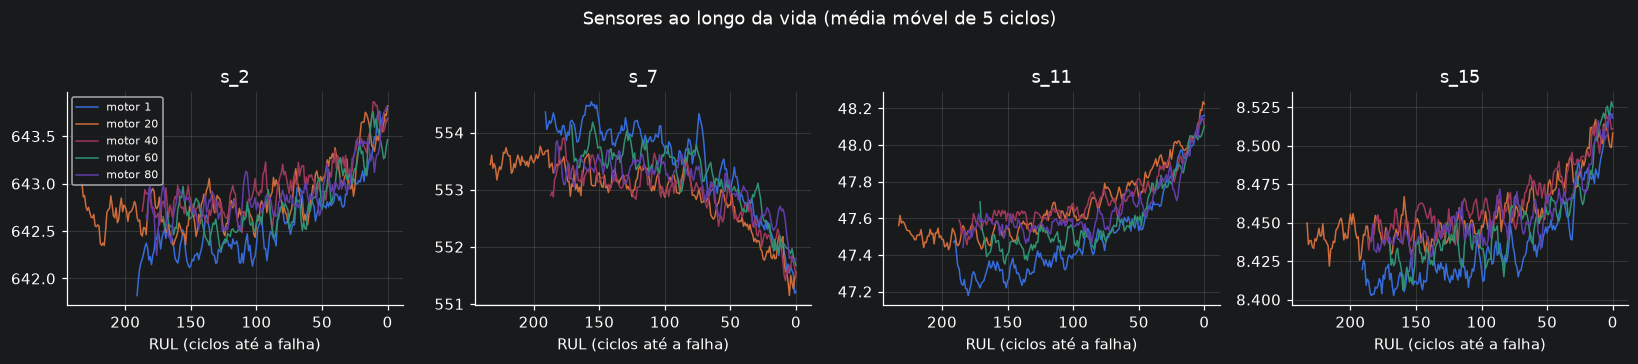

In [4]:
train_rul = add_train_rul(train)
sensores = ["s_2", "s_7", "s_11", "s_15"]
motores = [1, 20, 40, 60, 80]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharex=True)
for ax, s in zip(axes, sensores):
    for u in motores:
        d = train_rul[train_rul[ID_COL] == u].sort_values(CYCLE_COL)
        ax.plot(d["RUL"], d[s].rolling(5, min_periods=1).mean(), lw=1, label=f"motor {u}")
    ax.set_title(s); ax.set_xlabel("RUL (ciclos até a falha)")
axes[0].invert_xaxis()   # eixos compartilhados: inverter uma única vez (falha à direita)
axes[0].legend(fontsize=7)
fig.suptitle("Sensores ao longo da vida (média móvel de 5 ciclos)", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "01_sensores_por_rul.png", bbox_inches="tight"); plt.show()

Vários sensores mudam de forma monotônica perto da falha, mas só na fase final da vida do motor. Longe da falha, as trajetórias parecem se estabilizar (platô à esquerda da figura), de modo que os sensores distinguem pouco entre, por exemplo, 200 e 150 ciclos restantes. Isso motiva a análise do teto da RUL (seção 5).

## 4. Distribuição da RUL

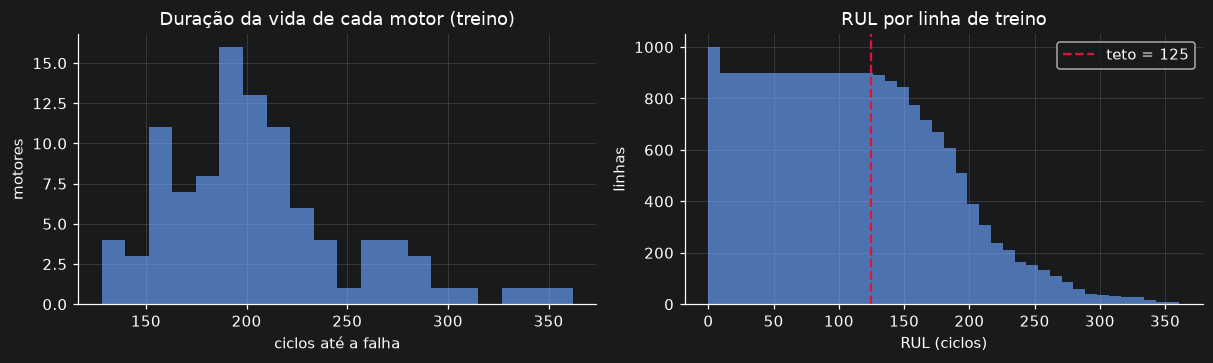

Linhas de treino com RUL > 125: 38.9%
RUL máxima no treino: 361 | vida mediana: 199 ciclos
RUL máxima informada para o teste oficial (arquivo RUL_FD001.txt): 145 ciclos


In [5]:
vida = train.groupby(ID_COL)[CYCLE_COL].max()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(vida, bins=20, color="#4C72B0")
axes[0].set(title="Duração da vida de cada motor (treino)", xlabel="ciclos até a falha", ylabel="motores")
axes[1].hist(train_rul["RUL"], bins=40, color="#4C72B0")
axes[1].axvline(CAP, color="crimson", ls="--", label=f"teto = {CAP}")
axes[1].set(title="RUL por linha de treino", xlabel="RUL (ciclos)", ylabel="linhas"); axes[1].legend()
fig.tight_layout(); fig.savefig(FIG / "02_distribuicao_rul.png", bbox_inches="tight"); plt.show()
print(f"Linhas de treino com RUL > {CAP}: {(train_rul['RUL'] > CAP).mean():.1%}")
print(f"RUL máxima no treino: {int(train_rul['RUL'].max())} | vida mediana: {vida.median():.0f} ciclos")
rul_teste = pd.read_csv(RAW / "RUL_FD001.txt", sep=r"\s+", header=None)[0]
print(f"RUL máxima informada para o teste oficial (arquivo RUL_FD001.txt): {int(rul_teste.max())} ciclos")

A RUL de treino chega a mais de 300 ciclos, mas o arquivo de RUL do teste oficial só traz valores até cerca de 145 (valor impresso acima). Uma fração relevante das linhas de treino fica em uma região em que os sensores ainda não mostram degradação. Esse contraste é a base da comparação com e sem teto.

## 5. Atributos e validação cruzada

Atributos por motor, usando só o passado: valor atual, média, desvio e tendência em janela retrospectiva de 5 ciclos, mais o número do ciclo (idade do motor).

In [6]:
train_feat, test_feat, true_rul = md.prepare()
todas = get_feature_columns(train_feat)
feature_cols = md.select_features(train_feat)
print(f"Atributos antes da remoção de constantes: {len(todas)} | depois: {len(feature_cols)}")

Atributos antes da remoção de constantes: 97 | depois: 69


In [7]:
cv_none = md.evaluate_group_cv(train_feat, feature_cols, cap=None).assign(variant="sem teto")
cv_cap = md.evaluate_group_cv(train_feat, feature_cols, cap=CAP).assign(variant=f"teto {CAP}")
cv_all = pd.concat([cv_none, cv_cap], ignore_index=True)
cv_all.to_csv(REPORTS / "cap_comparison.csv", index=False)

cols = {
    "baseline_rmse_le150": "RMSE baseline (RUL ≤ 150)",
    "model_rmse_le150": "RMSE modelo (RUL ≤ 150)",
    "model_bias_le150": "viés modelo (RUL ≤ 150)",
    "model_mae_0_50": "MAE 0–50", "model_mae_50_100": "MAE 50–100", "model_mae_100_150": "MAE 100–150",
    "model_mae": "MAE (todas as linhas)",
}
g = cv_all.groupby("variant")[list(cols)]
mean, std = g.mean(), g.std()
tabela = mean.round(1).astype(str) + " ± " + std.round(1).astype(str)
display(tabela.rename(columns=cols).T)

variant,sem teto,teto 125
RMSE baseline (RUL ≤ 150),51.9 ± 0.0,51.9 ± 0.0
RMSE modelo (RUL ≤ 150),28.7 ± 4.3,20.1 ± 1.4
viés modelo (RUL ≤ 150),10.6 ± 5.6,-0.2 ± 3.6
MAE 0–50,10.2 ± 1.9,9.4 ± 1.9
MAE 50–100,24.7 ± 3.4,18.0 ± 1.2
MAE 100–150,28.6 ± 3.8,18.0 ± 1.9
MAE (todas as linhas),27.5 ± 1.9,32.1 ± 1.0


**Como ler.** As colunas "RUL ≤ 150" e por faixa avaliam a região que importa para decidir manutenção (e que existe no teste oficial). O MAE sobre todas as linhas inclui motores muito longe da falha, com RUL real acima de 150, que não aparecem no teste; por isso ele sozinho engana.

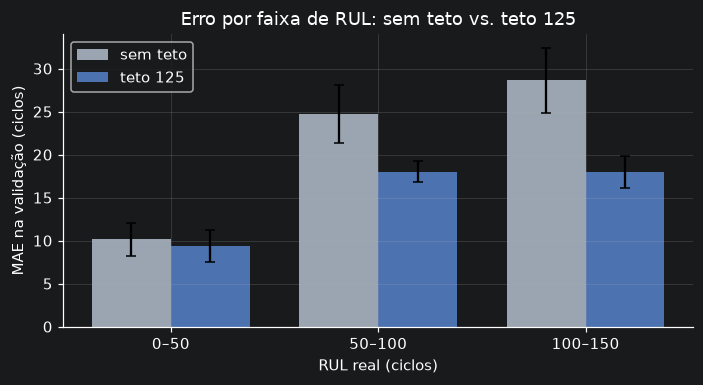

In [8]:
faixas = ["model_mae_0_50", "model_mae_50_100", "model_mae_100_150"]
rotulos = ["0–50", "50–100", "100–150"]
x = np.arange(len(faixas)); w = 0.38
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for i, (nome, cor) in enumerate([("sem teto", "#9aa5b1"), (f"teto {CAP}", "#4C72B0")]):
    d = cv_all[cv_all["variant"] == nome][faixas]
    ax.bar(x + (i - 0.5) * w, d.mean(), w, yerr=d.std(), capsize=3, label=nome, color=cor)
ax.set_xticks(x, rotulos); ax.set_xlabel("RUL real (ciclos)"); ax.set_ylabel("MAE na validação (ciclos)")
ax.set_title("Erro por faixa de RUL: sem teto vs. teto 125"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "03_cv_teto_por_faixa.png", bbox_inches="tight"); plt.show()

### Baseline vs. modelo, partição a partição (variante final)

In [9]:
cap_id = f"teto {CAP}"
por_particao = cv_all[cv_all["variant"] == cap_id].set_index("fold")[
    ["validation_engines", "baseline_rmse_le150", "model_rmse_le150", "baseline_mae", "model_mae"]
].round(1)
por_particao["modelo melhor?"] = por_particao["model_rmse_le150"] < por_particao["baseline_rmse_le150"]
display(por_particao)
print("Partições em que o modelo vence o baseline (RMSE, RUL ≤ 150):",
      int(por_particao["modelo melhor?"].sum()), "de", len(por_particao))

,validation_engines,baseline_rmse_le150,model_rmse_le150,baseline_mae,model_mae,modelo melhor?
fold,,,,,,
1,20,51.9,20.0,57.5,33.2,True
2,20,51.8,19.4,56.9,32.1,True
3,20,51.9,21.3,56.8,33.0,True
4,20,51.9,18.2,56.4,30.8,True
5,20,51.9,21.6,56.1,31.7,True


Partições em que o modelo vence o baseline (RMSE, RUL ≤ 150): 5 de 5


### O número do ciclo ajuda? (variante com teto, só validação cruzada)

In [10]:
sem_ciclo = [c for c in feature_cols if c != CYCLE_COL]
cv_sem_ciclo = md.evaluate_group_cv(train_feat, sem_ciclo, cap=CAP)
comp = pd.DataFrame({
    "com número do ciclo": cv_cap["model_rmse_le150"].agg(["mean", "std"]),
    "sem número do ciclo": cv_sem_ciclo["model_rmse_le150"].agg(["mean", "std"]),
}).round(1)
comp.index = ["RMSE (RUL ≤ 150), média", "RMSE (RUL ≤ 150), desvio entre partições"]
display(comp)

,com número do ciclo,sem número do ciclo
"RMSE (RUL ≤ 150), média",20.1,22.3
"RMSE (RUL ≤ 150), desvio entre partições",1.4,0.8


## 6. Escolha da variante final

In [11]:
resumo_var = mean.copy()
melhor = resumo_var["model_rmse_le150"].idxmin()
outro = [v for v in resumo_var.index if v != melhor][0]
r = lambda v, c: resumo_var.loc[v, c]
display(Markdown(
    f"**Variante escolhida: {melhor}.** Na validação cruzada por motor, o RMSE na região de interesse "
    f"(RUL real ≤ 150) caiu de {r(outro,'model_rmse_le150'):.1f} ({outro}) para {r(melhor,'model_rmse_le150'):.1f} ({melhor}) ciclos, "
    f"e o viés passou de {r(outro,'model_bias_le150'):+.1f} para {r(melhor,'model_bias_le150'):+.1f} ciclos. "
    f"O MAE sobre **todas** as linhas ficou em {r(melhor,'model_mae'):.1f} contra {r(outro,'model_mae'):.1f}: esse número "
    f"inclui linhas de RUL muito alta, ausentes do teste, e não foi usado como critério."
))
assert (melhor == f"teto {CAP}") == (md.RUL_CAP is not None), "Atualize RUL_CAP em src/modeling.py conforme a decisão."

**Variante escolhida: teto 125.** Na validação cruzada por motor, o RMSE na região de interesse (RUL real ≤ 150) caiu de 28.7 (sem teto) para 20.1 (teto 125) ciclos, e o viés passou de +10.6 para -0.2 ciclos. O MAE sobre **todas** as linhas ficou em 32.1 contra 27.5: esse número inclui linhas de RUL muito alta, ausentes do teste, e não foi usado como critério.

**Justificativa técnica.**
- Longe da falha os sensores não mostram degradação (seção 3); aprender RULs de 200 a 360 ciclos nessa região força o modelo a adivinhar, e os erros aparecem como superestimação da vida restante.
- Superestimar a RUL é o erro mais caro em manutenção, e o escore assimétrico do C-MAPSS o penaliza mais.
- Limitar o alvo é uma prática comum com o C-MAPSS. O valor 125 é uma convenção; não foi otimizado, para evitar ajustar a mais com poucos motores.
- O número do ciclo (idade) foi mantido como atributo: a comparação acima, feita só na validação, mostra o efeito de removê-lo.

**Transparência.** Ao revisar o modelo inicial (sem teto), os erros do teste oficial foram inspecionados de forma diagnóstica, e isso levantou a hipótese do teto. A decisão acima foi tomada com a validação cruzada. Nenhum hiperparâmetro foi ajustado com base no teste.

## 7. Teste oficial (uma única avaliação)

In [12]:
md.main()   # treina o modelo final, avalia no teste oficial e grava os arquivos em reports/
metricas = json.loads((REPORTS / "test_metrics.json").read_text(encoding="utf-8"))
pred = pd.read_csv(REPORTS / "test_predictions.csv")

CV (teto=125) salvo em reports/cv_metrics.csv
Métricas do teste oficial: {
  "mae": 13.806709953638938,
  "rmse": 18.683595167602977,
  "cmapss_score": 612.4413204765316,
  "n": 100,
  "bias": -0.6208199830843185,
  "share_overestimated": 0.51,
  "baseline": {
    "mae": 39.08,
    "rmse": 49.81987555183172,
    "cmapss_score": 166570.54261288798,
    "n": 100
  },
  "rul_cap": 125
}
Previsões salvas em reports/test_predictions.csv
Não ajuste o modelo com base nos resultados do teste oficial.


In [13]:
b, m = metricas["baseline"], metricas
tab = pd.DataFrame({
    "baseline (mediana)": [b["mae"], b["rmse"], b["cmapss_score"]],
    f"modelo ({melhor})": [m["mae"], m["rmse"], m["cmapss_score"]],
}, index=["MAE (ciclos)", "RMSE (ciclos)", "escore C-MAPSS"]).round(1)
display(tab)
print(f"Viés médio (previsto − real): {m['bias']:+.1f} ciclos | motores superestimados: {m['share_overestimated']:.0%}")

,baseline (mediana),modelo (teto 125)
MAE (ciclos),39.1,13.8
RMSE (ciclos),49.8,18.7
escore C-MAPSS,166570.5,612.4


Viés médio (previsto − real): -0.6 ciclos | motores superestimados: 51%


In [14]:
pred["faixa"] = pd.cut(pred["rul_true"], [0, 30, 60, 100, 150], labels=["7–30", "31–60", "61–100", "101–145"])
por_faixa = pred.groupby("faixa", observed=True).agg(
    motores=("unit_nr", "count"),
    mae=("error_pred_minus_true", lambda s: s.abs().mean()),
    vies=("error_pred_minus_true", "mean"),
).round(1)
display(por_faixa)
print("Maiores erros absolutos:")
display(pred.reindex(pred["error_pred_minus_true"].abs().sort_values(ascending=False).index)
        .head(5)[["unit_nr", "last_observed_cycle", "rul_true", "rul_pred", "error_pred_minus_true"]].round(1))

,motores,mae,vies
faixa,,,
7–30,25,8.0,5.7
31–60,14,9.2,4.0
61–100,28,15.9,4.7
101–145,33,18.4,-11.9


Maiores erros absolutos:


,unit_nr,last_observed_cycle,rul_true,rul_pred,error_pred_minus_true
73,74,137,126,72.1,-53.9
44,45,152,114,61.3,-52.7
88,89,177,136,86.4,-49.6
66,67,71,77,116.2,39.2
36,37,121,21,58.7,37.7


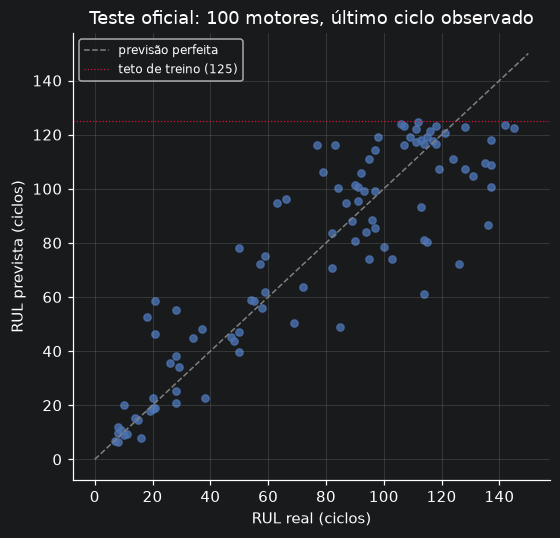

In [15]:
fig, ax = plt.subplots(figsize=(5.2, 5))
lim = max(pred["rul_true"].max(), pred["rul_pred"].max()) + 5
ax.plot([0, lim], [0, lim], color="gray", ls="--", lw=1, label="previsão perfeita")
ax.scatter(pred["rul_true"], pred["rul_pred"], s=22, alpha=0.8, color="#4C72B0")
ax.axhline(CAP, color="crimson", lw=0.8, ls=":", label=f"teto de treino ({CAP})")
ax.set(xlabel="RUL real (ciclos)", ylabel="RUL prevista (ciclos)", title="Teste oficial: 100 motores, último ciclo observado")
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(FIG / "04_rul_real_vs_prevista.png", bbox_inches="tight"); plt.show()

## 8. Conclusões e limitações

- O modelo supera o baseline em todas as partições e no teste oficial; o ganho é maior na fase em que os sensores já mostram degradação.
- Os maiores erros aparecem nas faixas de RUL mais altas, onde há pouco sinal nos sensores; na faixa final (poucos ciclos antes da falha), o erro é pequeno. Isso é desejável para manutenção, mas é uma observação sobre este conjunto simulado.
- Com o teto, o modelo tende a subestimar a RUL de motores ainda muito saudáveis (viés negativo na última faixa da tabela do teste), um erro conservador do ponto de vista de manutenção, mas que gera intervenções antecipadas.
- **Limitações:** dados simulados de um único subconjunto (FD001: uma condição operacional e um modo de falha); 100 motores de teste; o escore assimétrico depende de poucos erros grandes; nenhuma incerteza foi estimada para as previsões; hiperparâmetros fixos, sem busca.
- **Próximo passo (notebook 02):** usar a RUL prevista como indicador de urgência na priorização multicritério.